# DSCI 552 - Homework 5

- **Name:** Jesse Fulcher
- **GitHub Username:** jfulch
- **USC ID:** 7451-9585-45

## Decision Trees as Interpretable Models

### 1(a) - Download the Accute Inflamations data from https://archive.ics.uci.edu/ml/datasets/Acute+Inflammations.

In [1]:
from pathlib import Path
import pandas as pd

data_path = Path("../data/diagnosis.data")

columns = [
    "temperature",
    "nausea",
    "lumbar_pain",
    "urine_pushing",
    "micturition_pains",
    "burning_of_urethra",
    "bladder_inflammation",
    "nephritis"
]

acute_df = pd.read_csv(
    data_path,
    sep="\t",
    encoding="utf-16",
    decimal=",",
    header=None,
    names=columns
)

display(acute_df.head())
print(f"Dataset shape: {acute_df.shape}")
print(f"Missing values: {acute_df.isna().sum().sum()}")

,temperature,nausea,lumbar_pain,urine_pushing,micturition_pains,burning_of_urethra,bladder_inflammation,nephritis
0,35.5,no,yes,no,no,no,no,no
1,35.9,no,no,yes,yes,yes,yes,no
2,35.9,no,yes,no,no,no,no,no
3,36.0,no,no,yes,yes,yes,yes,no
4,36.0,no,yes,no,no,no,no,no


Dataset shape: (120, 8)
Missing values: 0


### 1(b) - Build a decision tree on the whole data set and plot it.

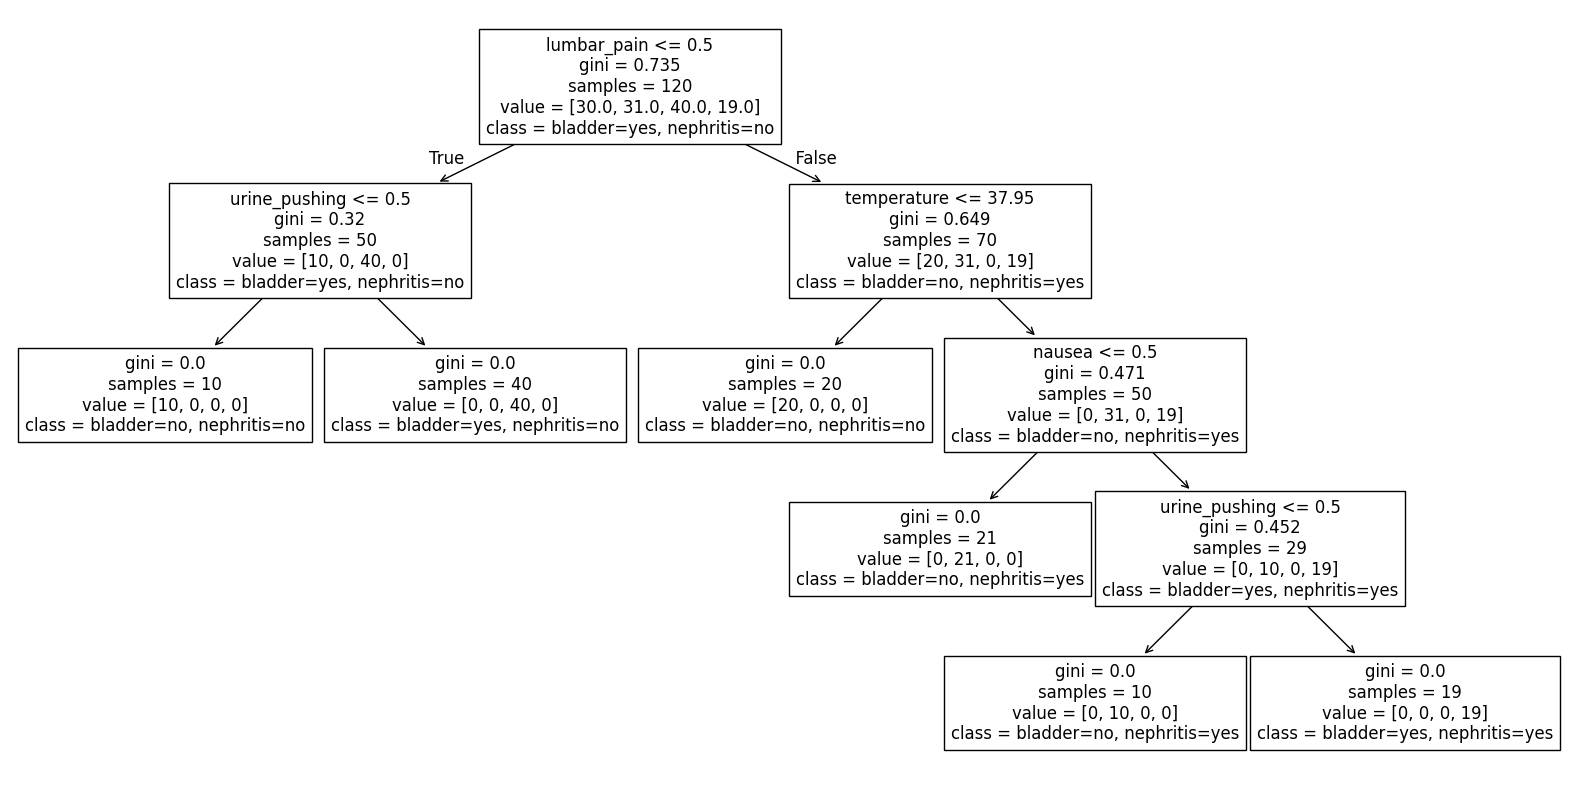

In [2]:
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier, plot_tree

x = acute_df.iloc[:, :6].copy()

for column in x.columns[1:]:
    x[column] = x[column].map({"yes": 1, "no": 0})

y = (
    "bladder=" + acute_df["bladder_inflammation"].astype(str) + ", nephritis=" + acute_df["nephritis"].astype(str)
)

tree_model = DecisionTreeClassifier(random_state=42)
tree_model.fit(x, y)

plt.figure(figsize=(20, 10))

plot_tree(
    tree_model, 
    feature_names=x.columns,
    class_names=tree_model.classes_.tolist()
)
plt.show()

### 1(c) - Convert the decision rules into a set of IF-THEN rules.

In [3]:
def get_if_then_rules(model, feature_names):
    tree_ = model.tree_
    rules = []

    def walk(node, conditions):
        left = tree_.children_left[node]
        right = tree_.children_right[node]

        if left == right:
            class_index = tree_.value[node][0].argmax()
            prediction = model.classes_[class_index]
            conditions_str = " AND ".join(conditions) if conditions else "TRUE"
            rules.append(f"IF {conditions_str} THEN {prediction}")
            return
        
        feature = feature_names[tree_.feature[node]]
        threshold = tree_.threshold[node]

        walk(left, conditions + [f"{feature} <= {threshold}"])
        walk(right, conditions + [f"{feature} > {threshold}"])

    walk(0, [])
    return rules

rules = get_if_then_rules(tree_model, x.columns.tolist())

for number, rule in enumerate(rules, start=1):
    print(f"{number}. {rule}")


1. IF lumbar_pain <= 0.5 AND urine_pushing <= 0.5 THEN bladder=no, nephritis=no
2. IF lumbar_pain <= 0.5 AND urine_pushing > 0.5 THEN bladder=yes, nephritis=no
3. IF lumbar_pain > 0.5 AND temperature <= 37.95000076293945 THEN bladder=no, nephritis=no
4. IF lumbar_pain > 0.5 AND temperature > 37.95000076293945 AND nausea <= 0.5 THEN bladder=no, nephritis=yes
5. IF lumbar_pain > 0.5 AND temperature > 37.95000076293945 AND nausea > 0.5 AND urine_pushing <= 0.5 THEN bladder=no, nephritis=yes
6. IF lumbar_pain > 0.5 AND temperature > 37.95000076293945 AND nausea > 0.5 AND urine_pushing > 0.5 THEN bladder=yes, nephritis=yes


### 1(d) - Use cost-complexity pruning to find a minimal decision tree and a set of decision rules with high interpretability

In [4]:
import numpy as np
from sklearn.model_selection import StratifiedKFold, cross_val_score

path = tree_model.cost_complexity_pruning_path(x, y)

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

results = []

for alpha in np.unique(path.ccp_alphas):
    model = DecisionTreeClassifier(
        ccp_alpha=float(alpha),
        random_state=42
    )

    scores = cross_val_score(
        model, x, 
        y, 
        cv=cv,
        scoring="accuracy"
    )

    model.fit(x, y)

    results.append({
        "alpha": float(alpha),
        "mean_cv_accuracy": scores.mean(),
        "standard_error": scores.std(ddof=1) / np.sqrt(len(scores)),
        "leaves": model.get_n_leaves(),
        "depth": model.get_depth()
    })

pruning_results = pd.DataFrame(results)

best_index = pruning_results["mean_cv_accuracy"].idxmax()
best_result = pruning_results.loc[best_index]

cutoff = (
    best_result["mean_cv_accuracy"] - best_result["standard_error"]
)

eligible = pruning_results[
    pruning_results["mean_cv_accuracy"] >= cutoff
]

selected = eligible.sort_values(
    by=["leaves","alpha"]
).iloc[0]

selected_alpha = float(selected["alpha"])

display(pruning_results)
print(f"Selected alpha: {selected_alpha:.6f}")
print(f"Selected mean CV accuracy: {selected['mean_cv_accuracy']:.3f}")

,alpha,mean_cv_accuracy,standard_error,leaves,depth
0,0.000000,0.991667,0.008333,6,4
1,0.098167,0.858333,0.025000,4,2
2,0.133333,0.758333,0.033333,3,2
3,0.182000,0.666667,0.029463,2,1
4,0.222917,0.483333,0.061237,1,0


Selected alpha: 0.000000
Selected mean CV accuracy: 0.992


Original tree: depth=4, leaves=6
Selected tree: depth=4, leaves=6


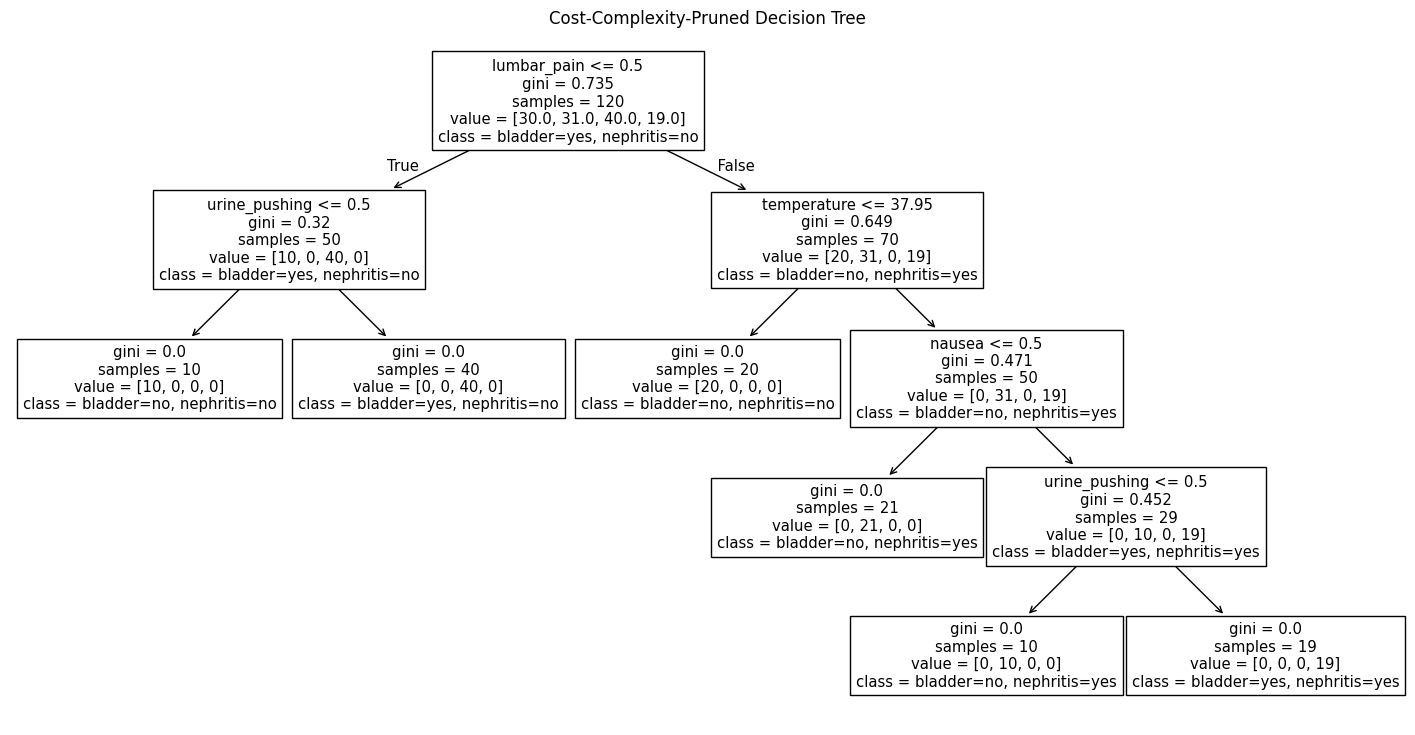

In [5]:
pruned_tree = DecisionTreeClassifier(
    random_state=42,
    ccp_alpha=selected_alpha,
)

pruned_tree.fit(x, y)

print(
    f"Original tree: depth={tree_model.get_depth()}, "
    f"leaves={tree_model.get_n_leaves()}"
)
print(
    f"Selected tree: depth={pruned_tree.get_depth()}, "
    f"leaves={pruned_tree.get_n_leaves()}"
)

plt.figure(figsize=(18, 9))

plot_tree(
    pruned_tree,
    feature_names=x.columns.tolist(),
    class_names=pruned_tree.classes_.tolist()
)

plt.title("Cost-Complexity-Pruned Decision Tree")
plt.show()

In [20]:
for number, rule in enumerate(
    get_if_then_rules(pruned_tree, x.columns.tolist()),
    start=1,
):
    print(f"{number}. {rule}")

1. IF lumbar_pain <= 0.5 AND urine_pushing <= 0.5 THEN bladder=no, nephritis=no
2. IF lumbar_pain <= 0.5 AND urine_pushing > 0.5 THEN bladder=yes, nephritis=no
3. IF lumbar_pain > 0.5 AND temperature <= 37.95000076293945 THEN bladder=no, nephritis=no
4. IF lumbar_pain > 0.5 AND temperature > 37.95000076293945 AND nausea <= 0.5 THEN bladder=no, nephritis=yes
5. IF lumbar_pain > 0.5 AND temperature > 37.95000076293945 AND nausea > 0.5 AND urine_pushing <= 0.5 THEN bladder=no, nephritis=yes
6. IF lumbar_pain > 0.5 AND temperature > 37.95000076293945 AND nausea > 0.5 AND urine_pushing > 0.5 THEN bladder=yes, nephritis=yes


## 2. The LASSO and Boosting for Regression


### 2(a) - Download the Communities and Crime data3 from https://archive.ics.uci. edu/ml/datasets/Communities+and+Crime. Use the first 1495 rows of data as the training set and the rest as the test set.

In [6]:
communities_df = pd.read_csv("../data/communities.data", header=None, na_values="?")

train_df = communities_df.iloc[:1495].copy()
test_df = communities_df.iloc[1495:].copy()

### 2(b) - The data set has missing values. Use a data imputation technique to deal with the missing values in the data set. The data description mentions some features are nonpredictive. Ignore those features

In [7]:
from sklearn.impute import SimpleImputer

x_train = train_df.iloc[:, 5:-1].copy()
x_test = test_df.iloc[:, 5:-1].copy()

y_train = train_df.iloc[:, -1].copy()
y_test = test_df.iloc[:, -1].copy()

imputer = SimpleImputer(strategy="median", keep_empty_features=True)

x_train = pd.DataFrame(
    imputer.fit_transform(x_train),
    columns=x_train.columns,
    index=x_train.index,
)

x_test = pd.DataFrame(
    imputer.transform(x_test),
    columns=x_test.columns,
    index=x_test.index,
)

### 2(c) Plot a correlation matrix for the features in the data set.

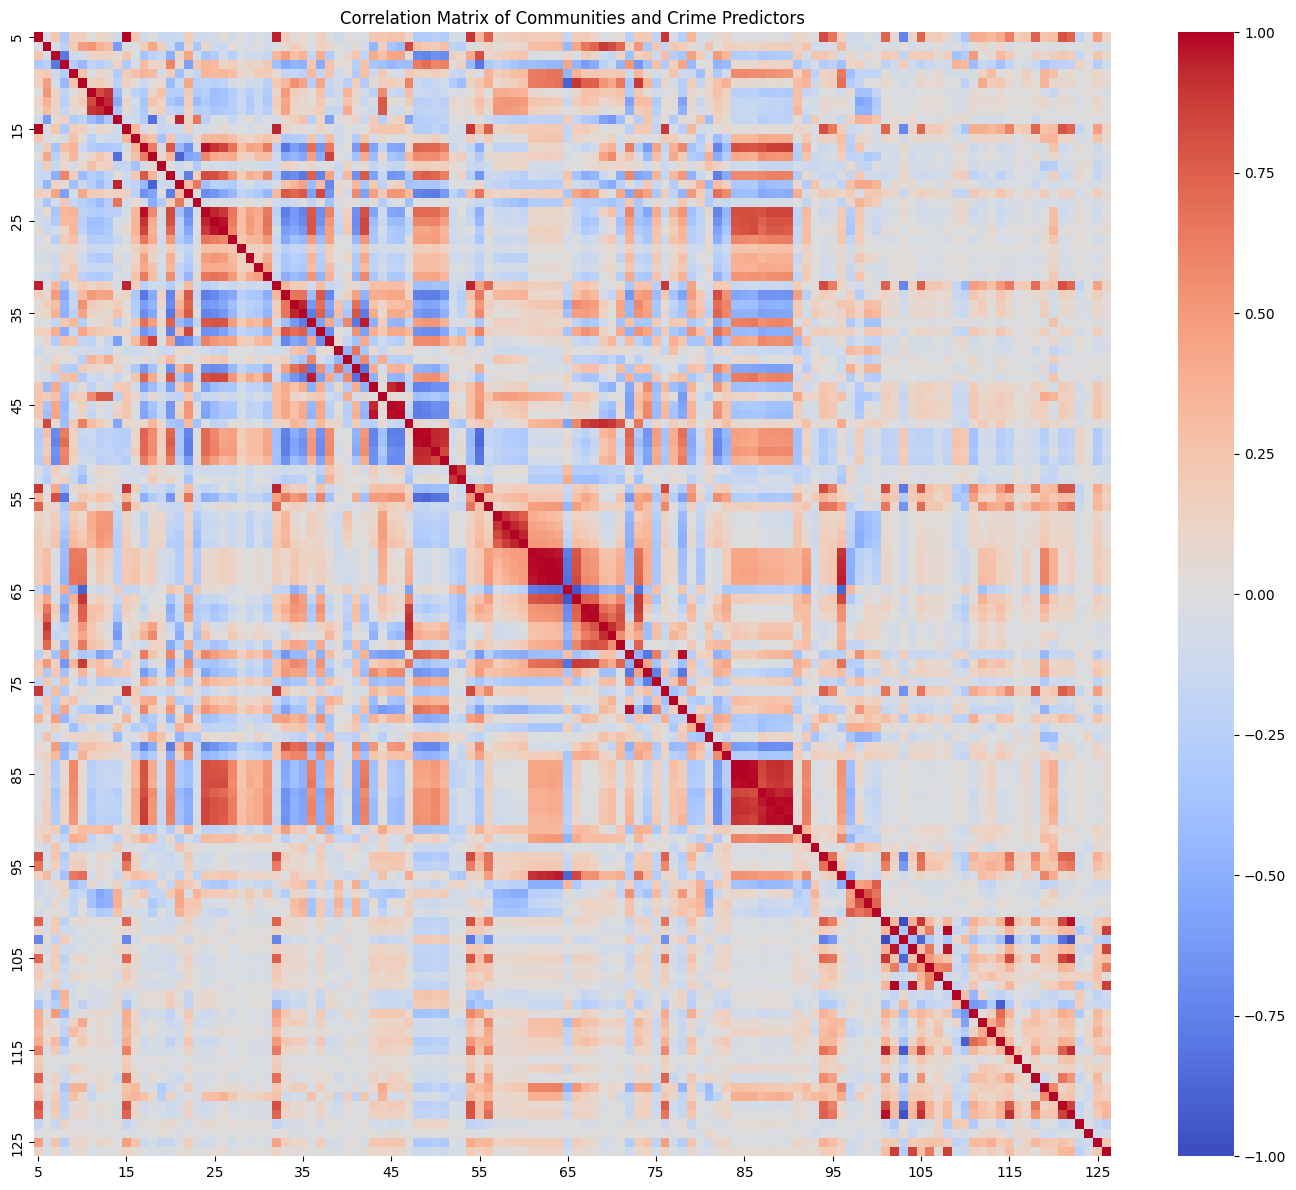

In [8]:
import seaborn as sns
import matplotlib.pyplot as plt

correlation_matrix = x_train.corr()

plt.figure(figsize=(14, 12))

sns.heatmap(
    correlation_matrix,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    xticklabels=10,
    yticklabels=10,
)

plt.title("Correlation Matrix of Communities and Crime Predictors")
plt.tight_layout()
plt.show()

### 2(d) Calculate the Coefficient of Variation CV for each feature, where CV = s m , in which s is sample standard deviation and m is sample mean.

In [9]:
feature_means = x_train.mean()
feature_stds = x_train.std(ddof=1)

cv = feature_stds / feature_means.replace(0, float("nan"))

cv_table = pd.DataFrame({
    "mean": feature_means,
    "sample_std": feature_stds,
    "CV": cv
})

display(cv_table)

,mean,sample_std,CV
5,0.058167,0.130359,2.241105
6,0.461732,0.164284,0.355800
7,0.179839,0.256970,1.428885
8,0.752829,0.248594,0.330213
9,0.153712,0.208910,1.359100
...,...,...,...
122,0.038074,0.062650,1.645508
123,0.752495,0.084304,0.112032
124,0.492308,0.164974,0.335104
125,0.093304,0.238201,2.552946


### 2(e) Pick b√128c features with highest CV , and make scatter plots and box plots for them. Can you draw conclusions about significance of those features, just by the scatter plots?

In [10]:
top_features = cv.dropna().nlargest(11).index

display(cv_table.loc[top_features])

,mean,sample_std,CV
113,0.016254,0.089838,5.527059
95,0.022983,0.098665,4.292923
94,0.029599,0.102736,3.470952
54,0.037204,0.113806,3.058964
56,0.030595,0.089541,2.926635
125,0.093304,0.238201,2.552946
32,0.056849,0.133167,2.342443
101,0.028749,0.064629,2.248042
5,0.058167,0.130359,2.241105
15,0.064649,0.131784,2.038461


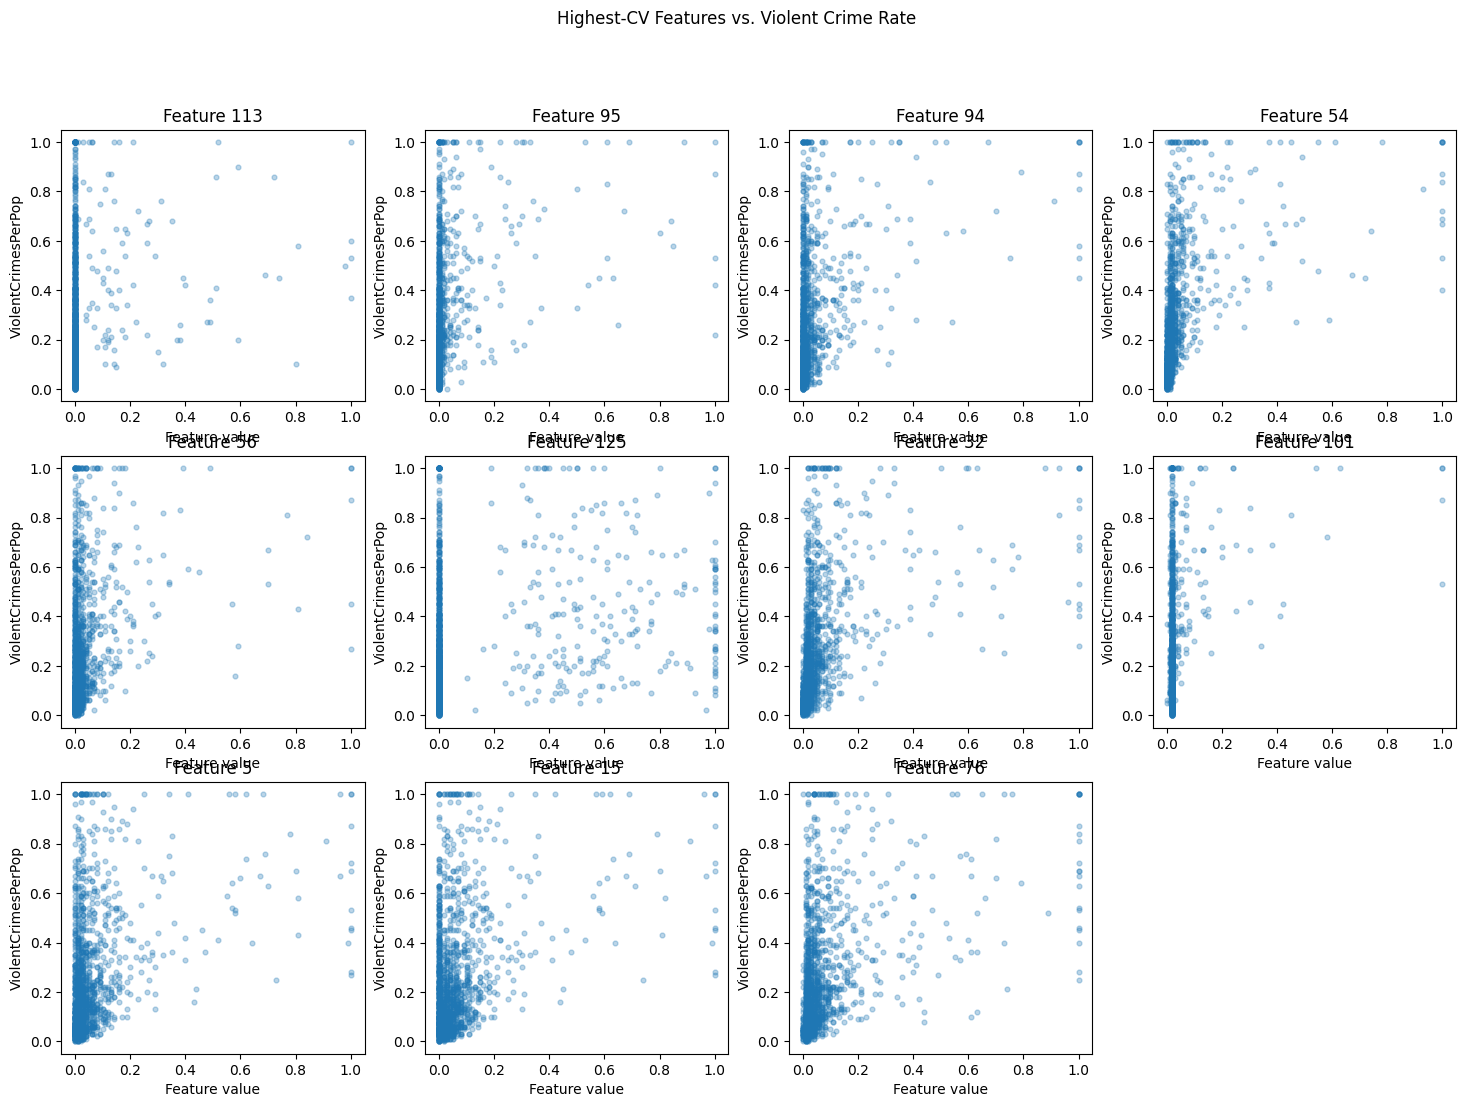

In [11]:
fig, axes = plt.subplots(3, 4, figsize=(18, 12))

for ax, feature in zip(axes.flat, top_features):
    ax.scatter(x_train[feature], y_train, alpha=0.3, s=12)
    ax.set_title(f"Feature {feature}")
    ax.set_xlabel("Feature value")
    ax.set_ylabel("ViolentCrimesPerPop")

for ax in axes.flat[len(top_features):]:
    ax.set_visible(False)

fig.suptitle("Highest-CV Features vs. Violent Crime Rate")
plt.show()

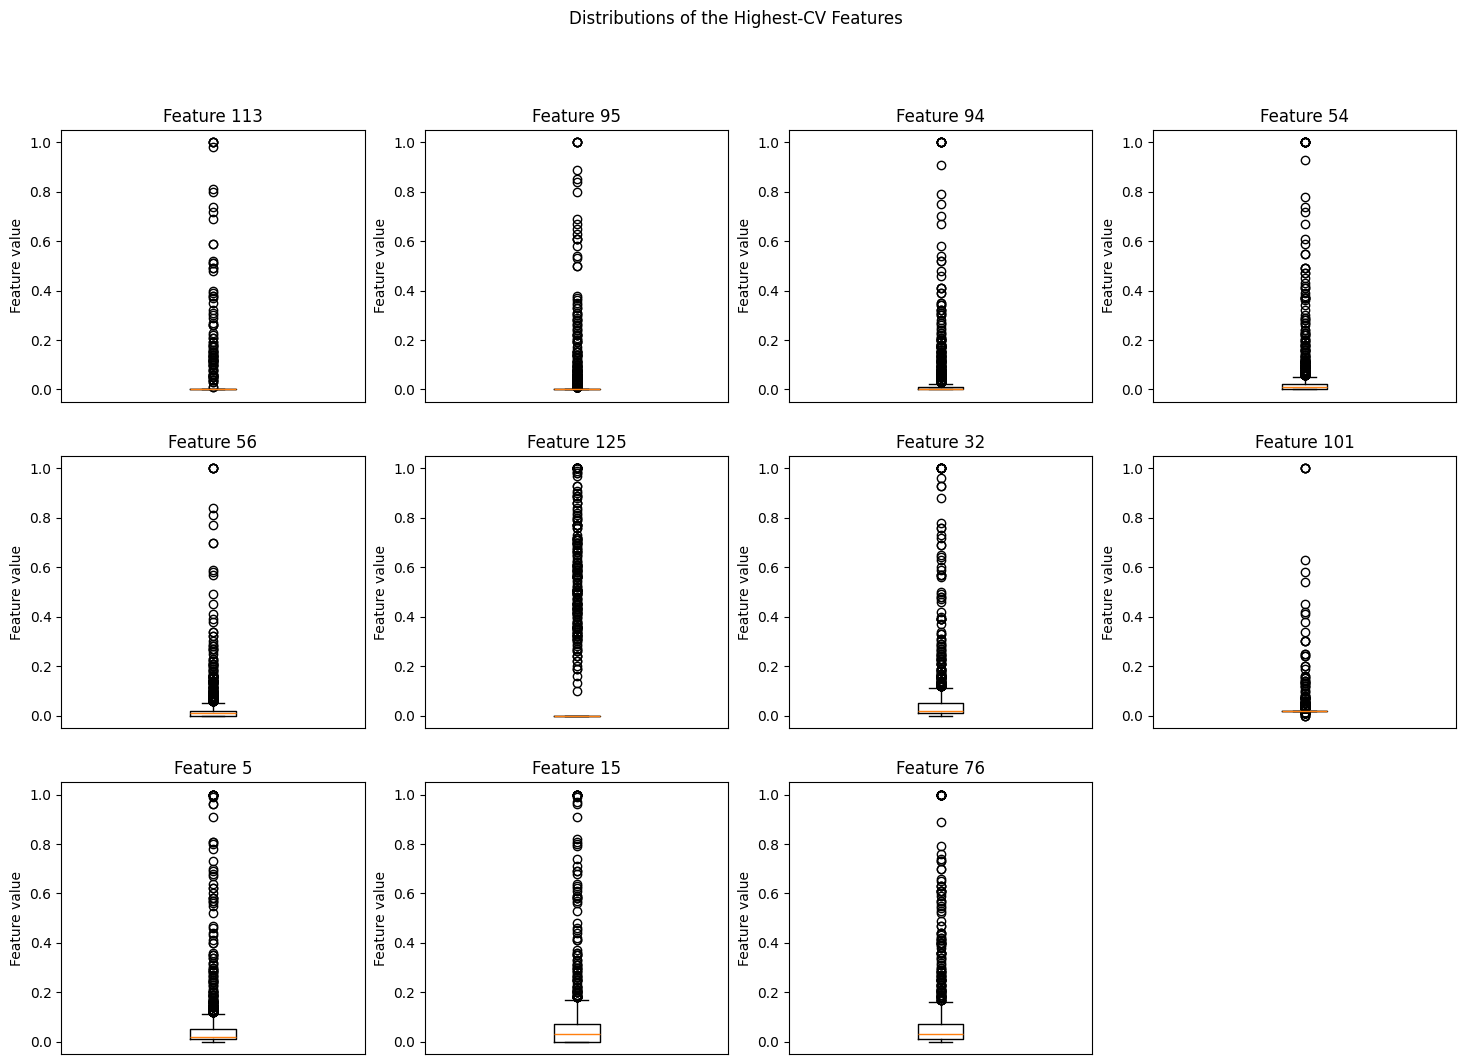

In [12]:
fig, axes = plt.subplots(3, 4, figsize=(18, 12))

for ax, feature in zip(axes.flat, top_features):
    ax.boxplot(x_train[feature].dropna())
    ax.set_title(f"Feature {feature}")
    ax.set_xticks([])
    ax.set_ylabel("Feature value")

for ax in axes.flat[len(top_features):]:
    ax.set_visible(False)

fig.suptitle("Distributions of the Highest-CV Features")
plt.show()

Answer: The scatter plots can suggest relationships between predictors and violent crime rates, but they cannot establish statistical significance. They do not account for other predictors or confounding. A high coefficient of variation also does not necessarily imply predictive importance.

### 2(f) Fit a linear model using least squares to the training set and report the test error.

In [13]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error

linear_model = LinearRegression()
linear_model.fit(x_train, y_train)

linear_predictions = linear_model.predict(x_test)
linear_test_mse = mean_squared_error(y_test, linear_predictions)

print(f"Least-squares test MSE: {linear_test_mse:.6f}")

Least-squares test MSE: 0.017966


### 2(g) Fit a ridge regression model on the training set, with λ chosen by cross-validation. Report the test error obtained.

In [14]:
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.model_selection import GridSearchCV, KFold
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_squared_error
from sklearn.preprocessing import StandardScaler

x_train_raw = train_df.iloc[:, 5:-1].copy()
x_test_raw = test_df.iloc[:, 5:-1].copy()

ridge_pipeline = Pipeline([
    ("imputer", SimpleImputer(
        strategy="median",
        keep_empty_features=True,
    )),
    ("scaler", StandardScaler()),
    ("ridge", Ridge()),
])

regression_cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42,
)

ridge_search = GridSearchCV(
    ridge_pipeline,
    param_grid={"ridge__alpha": np.logspace(-4, 4, 41)},
    scoring="neg_mean_squared_error",
    cv=regression_cv,
)

ridge_search.fit(x_train_raw, y_train)

ridge_predictions = ridge_search.predict(x_test_raw)
ridge_test_mse = mean_squared_error(y_test, ridge_predictions)

print(f"Selected lambda (alpha): {ridge_search.best_params_['ridge__alpha']:.6g}")
print(f"Cross-validation MSE: {-ridge_search.best_score_:.6f}")
print(f"Ridge test MSE: {ridge_test_mse:.6f}")

Selected lambda (alpha): 158.489
Cross-validation MSE: 0.019738
Ridge test MSE: 0.017343


### 2(h) Fit a LASSO model on the training set, with λ chosen by cross-validation. Report the test error obtained, along with a list of the variables selected by the model. Repeat with standardized4 features. Report the test error for both cases and compare them.

In [22]:
from sklearn.linear_model import Lasso

lasso_results = []
lasso_searches = {}

for standardized in [False, True]:
    label = "Standardized" if standardized else "Unstandardized"

    pipeline = Pipeline([
        ("imputer", SimpleImputer(
            strategy="median",
            keep_empty_features=True,
        )),
        ("scaler", StandardScaler() if standardized else "passthrough"),
        ("lasso", Lasso(max_iter=100000)),
    ])

    search = GridSearchCV(
        pipeline,
        param_grid={"lasso__alpha": np.logspace(-6, 0, 61)},
        scoring="neg_mean_squared_error",
        cv=regression_cv,
    )

    search.fit(x_train_raw, y_train)
    lasso_searches[label] = search

    predictions = search.predict(x_test_raw)
    test_mse = mean_squared_error(y_test, predictions)

    coefficients = pd.Series(
        search.best_estimator_.named_steps["lasso"].coef_,
        index=x_train_raw.columns,
    )

    selected = coefficients[coefficients != 0]

    lasso_results.append({
        "Model": label,
        "Selected alpha": search.best_params_["lasso__alpha"],
        "CV MSE": -search.best_score_,
        "Test MSE": test_mse,
        "Selected predictors": len(selected),
    })

    print(f"\n{label} LASSO: selected predictor coefficients")
    print(coefficients[coefficients != 0].to_string())

lasso_comparison = pd.DataFrame(lasso_results)
display(lasso_comparison)


Unstandardized LASSO: selected predictor coefficients
7      0.267226
9     -0.014299
11     0.057796
12    -0.246418
16     0.040553
18    -0.077498
19     0.025251
20    -0.096929
21     0.046862
22     0.038352
23    -0.106713
26    -0.053370
27    -0.021238
28    -0.030353
29     0.028394
30     0.022704
31     0.021848
33    -0.137176
34    -0.016826
38     0.128618
39    -0.014150
41     0.009707
43     0.112738
44     0.122957
45    -0.071979
49    -0.198127
50    -0.040026
51    -0.008217
53    -0.127173
54    -0.078805
55     0.101613
56    -0.082216
57    -0.000377
60    -0.003674
64     0.035904
66    -0.067283
68    -0.052529
69     0.030405
72    -0.053295
73     0.208528
74     0.053524
75     0.002154
76     0.122697
77    -0.061665
79     0.072546
80    -0.058247
81    -0.014117
82     0.023045
83    -0.023260
84    -0.008679
87    -0.153752
90     0.152525
91     0.089516
92    -0.011362
93    -0.076625
94     0.056232
95     0.156539
96     0.047517
97    -0.001164
9

,Model,Selected alpha,CV MSE,Test MSE,Selected predictors
0,Unstandardized,0.000126,0.019521,0.017616,74
1,Standardized,0.000631,0.019661,0.017723,76


In [16]:
with open("../data/communities.names") as file:
    community_names = [
        line.split()[1]
        for line in file
        if line.lower().startswith("@attribute")
    ]

for label, search in lasso_searches.items():
    coefficients = pd.Series(
        search.best_estimator_.named_steps["lasso"].coef_,
        index=[community_names[column] for column in x_train_raw.columns],
    )

    print(f"\n{label} LASSO: selected variables")
    display(
        coefficients[coefficients != 0]
        .rename("Coefficient")
        .to_frame()
    )


Unstandardized LASSO: selected variables


,Coefficient
racepctblack,0.267226
racePctAsian,-0.014299
agePct12t21,0.057796
agePct12t29,-0.246418
pctUrban,0.040553
...,...
PopDens,0.010487
PctUsePubTrans,-0.041957
PolicCars,0.013260
LemasPctPolicOnPatr,0.013913



Standardized LASSO: selected variables


,Coefficient
racepctblack,0.068043
racePctAsian,-0.001880
agePct12t21,0.012482
agePct12t29,-0.043284
pctUrban,0.017133
...,...
PopDens,0.003543
PctUsePubTrans,-0.009771
PolicCars,0.007769
LemasPctPolicOnPatr,0.001764


Answer: The unstandardized LASSO model had a slightly lower test MSE, although the difference was small. It retained 74 predictors, compared with 76 for the standardized model.

### 2(i) Fit a PCR model on the training set, with M (the number of principal components) chosen by cross-validation. Report the test error obtained.

In [17]:
from sklearn.decomposition import PCA

pcr_pipeline = Pipeline([
    ("imputer", SimpleImputer(
        strategy="median",
        keep_empty_features=True,
    )),
    ("scaler", StandardScaler()),
    ("pca", PCA(svd_solver="full")),
    ("regression", LinearRegression()),
])

pcr_search = GridSearchCV(
    pcr_pipeline,
    param_grid={
        "pca__n_components": range(1, x_train_raw.shape[1] + 1),
    },
    scoring="neg_mean_squared_error",
    cv=regression_cv,
)

pcr_search.fit(x_train_raw, y_train)

pcr_predictions = pcr_search.predict(x_test_raw)
pcr_test_mse = mean_squared_error(y_test, pcr_predictions)

print(f"Selected M: {pcr_search.best_params_['pca__n_components']}")
print(f"Cross-validation MSE: {-pcr_search.best_score_:.6f}")
print(f"PCR test MSE: {pcr_test_mse:.6f}")

Selected M: 60
Cross-validation MSE: 0.020210
PCR test MSE: 0.018350


### 2(j) In this section, we would like to fit a boosting tree to the data. As in classification trees, one can use any type of regression at each node to build a multivariate regression tree. Because the number of variables is large in this problem, one can use L1-penalized regression at each node. Such a tree is called L1 penalized gradient boosting tree. You can use XGBoost5 to fit the model tree. Determine α (the regularization term) using cross-validation.

In [18]:
%pip install xgboost


[notice] A new release of pip is available: 26.0.1 -> 26.2.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [19]:
from xgboost import XGBRegressor

boosting_pipeline = Pipeline([
    ("imputer", SimpleImputer(
        strategy="median",
        keep_empty_features=True,
    )),
    ("xgb", XGBRegressor(
        objective="reg:squarederror",
        booster="gbtree",
        n_estimators=300,
        learning_rate=0.05,
        max_depth=3,
        tree_method="hist",
        random_state=42,
        n_jobs=1,
    )),
])

boosting_search = GridSearchCV(
    boosting_pipeline,
    param_grid={
        "xgb__reg_alpha": np.concatenate(([0.0], np.logspace(-4, 2, 25))),
    },
    scoring="neg_mean_squared_error",
    cv=regression_cv,
)

boosting_search.fit(x_train_raw, y_train)

boosting_predictions = boosting_search.predict(x_test_raw)
boosting_test_mse = mean_squared_error(y_test, boosting_predictions)

print(f"Selected alpha: {boosting_search.best_params_['xgb__reg_alpha']:.6g}")
print(f"Cross-validation MSE: {-boosting_search.best_score_:.6f}")
print(f"XGBoost test MSE: {boosting_test_mse:.6f}")

Selected alpha: 0.1
Cross-validation MSE: 0.019907
XGBoost test MSE: 0.016422
